# Hafta 05: Ağ Katmanı (Network Layer) — Veri Düzlemi, IP Adresleme ve Yönlendirme Mimarisi

> **Ders Kitabı Referansı:** Computer Networking: A Top-Down Approach (J.F. Kurose, K.W. Ross — Bölüm 4)

---

## 1. Temel Ağ Katmanı İlkeleri ve Mimarisi

Uygulama katmanı süreçler arası mesajları tanımlarken, Taşıma katmanı (TCP/UDP) port numaraları ile bu mesajları uygulamadan uygulamaya iletir. **Ağ Katmanı (Network Layer)** ise paketlerin **cihazdan cihaza (Host-to-Host)**, küresel internetteki yüz milyonlarca yönlendirici üzerinden hedefine ulaştırılmasından sorumludur.

---

### 1.1. İki Kritik Fonksiyon: Routing (Yönlendirme) vs Forwarding (İletim)

Ağ katmanının işleyişi iki temel düzleme (Plane) ayrılır:

| Karşılaştırma Kriteri | İletim (Forwarding / Data Plane) | Yönlendirme (Routing / Control Plane) |
| :--- | :--- | :--- |
| **Kapsam** | **Yerel (Local):** Tek bir router içinde gerçekleşir. | **Ağ Geneli (Network-wide):** Tüm interneti kapsar. |
| **İşlev** | Router'ın giriş portuna gelen paketin başlığına bakıp uygun çıkış portuna aktarmasıdır. | Paketin kaynaktan hedefe izleyeceği en az maliyetli uçtan uca rotayı (*Route Path*) belirlemektir. |
| **Uygulama Şekli** | Donanımsal düzeyde (ASIC, TCAM çipleri) nanosaniyeler içinde çalışır. | Yazılımsal düzeyde (RIP, OSPF, BGP algoritmaları) saniyeler/dakikalar mertebesinde çalışır. |
| **Benzetme** | Bir kavşaktaki trafik polisinin aracı sağ şeride yönlendirmesi. | Şehirlerarası yolculuğa çıkmadan önce haritadan en uygun güzergâhı planlamak. |

---

### 1.2. Router İç Mimarisi ve Kuyruk (Queueing) Nerede Oluşur?

Bir yönlendirici üç temel bileşenden oluşur: **Giriş Portları (Input Ports)**, **Anahtarlama Dokusu (Switching Fabric)** ve **Çıkış Portları (Output Ports)**.
* **Giriş Kuyruğu (Input Queueing):** Anahtarlama dokusu giriş portlarından gelen hıza yetişemezse (*Head-of-Line Blocking*) giriş tamponlarında kuyruk birikir.
* **Çıkış Kuyruğu (Output Queueing):** Farklı girişlerden aynı çıkış linkine aynı anda paket akarsa, hattın fiziksel aktarım hızı yetersiz kaldığı için çıkış portunun belleğinde kuyruk oluşur.
* **Paket Kaybı (Packet Drop):** Bu tampon bellekler dolduğunda (*Buffer Overflow*) yeni gelen paketler router tarafından acımasızca çöpe atılır. Ağdaki paket kaybının birincil kaynağı yönlendirici tampon taşmalarıdır.

---

### 1.3. Datagram Ağları ve En Uzun Önek Eşleşmesi (Longest Prefix Match - LPM)

İnternet bir **Datagram Ağıdır (Bağlantısız - Connectionless)**. Paketler yola çıkmadan önce fiziksel bir hat rezerve edilmez; her paket bağımsız bir kargo gibi ağa bırakılır ve farklı güzergâhlardan geçebilir.

Router bir paketi çıkış portuna aktarırken **En Uzun Önek Eşleşmesi (Longest Prefix Match)** kuralını işletir:
* Bir IP adresinde soldan sağa gidildikçe konum genelden yerele (Ülke $\rightarrow$ Şehir $\rightarrow$ Kampüs $\rightarrow$ Alt Ağ) doğru daralır.
* Yönlendirme tablosunda hedef IP ile eşleşen birden fazla kural varsa; **en uzun benzerliğe (en dar alt ağ maskesine)** sahip kural seçilir.

> **Örnek:** Hedef IP `192.34.52.15` olsun. Tablodaki kurallar:
> 1. Kural: `192.34.52.0/22` $\rightarrow$ Link A
> 2. Kural: `192.34.52.0/24` $\rightarrow$ Link B
> 3. Kural: `0.0.0.0/0` (Default Gateway) $\rightarrow$ Link C
>
> Hedef IP her üç kurala da uyar. Ancak `/24` maskesi ilk 24 bitlik eşleşmeyle en uzun öneğe sahip olduğu için paket **Link B** üzerinden yönlendirilir.

---
## 2. Mimari Görselleştirmeler (Vektörel SVG)

Aşağıdaki kod hücreleri; Router İç Mimarisi ve Kuyruk Mekanizması, IPv4 Datagram Başlık Formatı (20 Bayt) ve DHCP / NAT Ağ Şemalarını DLL bağımsız saf SVG formatında ekrana basar.

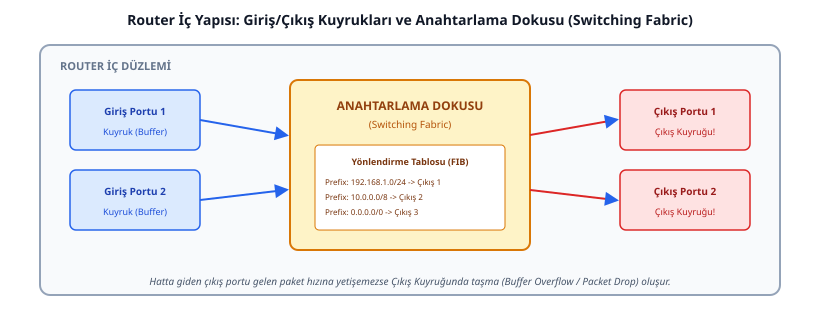

In [1]:
from IPython.display import SVG, display

# Şekil 1: Router İç Mimarisi, İletim (Forwarding) ve Kuyruk (Queueing) Noktaları
svg_router = """
<svg width="820" height="320" viewBox="0 0 820 320" xmlns="http://www.w3.org/2000/svg" style="background:#ffffff; font-family:sans-serif;">
  <defs>
    <marker id="arr-r" markerWidth="7" markerHeight="7" refX="5" refY="3.5" orient="auto">
      <polygon points="0 0, 7 3.5, 0 7" fill="#2563eb"/>
    </marker>
  </defs>
  <text x="410" y="25" text-anchor="middle" font-size="14" font-weight="bold" fill="#111827">
    Router İç Yapısı: Giriş/Çıkış Kuyrukları ve Anahtarlama Dokusu (Switching Fabric)
  </text>

  <!-- Router Dış Kasası -->
  <rect x="40" y="45" width="740" height="250" rx="10" fill="#f8fafc" stroke="#94a3b8" stroke-width="2"/>
  <text x="60" y="70" font-size="11" font-weight="bold" fill="#64748b">ROUTER İÇ DÜZLEMİ</text>

  <!-- GİRİŞ PORTLARI -->
  <g transform="translate(70, 90)">
    <rect width="130" height="60" rx="6" fill="#dbeafe" stroke="#2563eb" stroke-width="1.5"/>
    <text x="65" y="25" text-anchor="middle" font-size="10" font-weight="bold" fill="#1e40af">Giriş Portu 1</text>
    <text x="65" y="45" text-anchor="middle" font-size="9" fill="#1d4ed8">Kuyruk (Buffer)</text>
    
    <rect y="80" width="130" height="60" rx="6" fill="#dbeafe" stroke="#2563eb" stroke-width="1.5"/>
    <text x="65" y="105" text-anchor="middle" font-size="10" font-weight="bold" fill="#1e40af">Giriş Portu 2</text>
    <text x="65" y="125" text-anchor="middle" font-size="9" fill="#1d4ed8">Kuyruk (Buffer)</text>
  </g>

  <!-- ANAHTARLAMA DOKUSU (SWITCHING FABRIC) -->
  <g transform="translate(290, 80)">
    <rect width="240" height="170" rx="8" fill="#fef3c7" stroke="#d97706" stroke-width="2"/>
    <text x="120" y="30" text-anchor="middle" font-size="12" font-weight="bold" fill="#92400e">ANAHTARLAMA DOKUSU</text>
    <text x="120" y="48" text-anchor="middle" font-size="10" fill="#b45309">(Switching Fabric)</text>
    
    <!-- Yönlendirme Tablosu Kutusu -->
    <rect x="25" y="65" width="190" height="85" rx="4" fill="#ffffff" stroke="#d97706" stroke-width="1"/>
    <text x="120" y="85" text-anchor="middle" font-size="9" font-weight="bold" fill="#78350f">Yönlendirme Tablosu (FIB)</text>
    <text x="35" y="105" font-size="8" fill="#78350f">Prefix: 192.168.1.0/24 -&gt; Çıkış 1</text>
    <text x="35" y="120" font-size="8" fill="#78350f">Prefix: 10.0.0.0/8     -&gt; Çıkış 2</text>
    <text x="35" y="135" font-size="8" fill="#78350f">Prefix: 0.0.0.0/0      -&gt; Çıkış 3</text>
  </g>

  <!-- ÇIKIŞ PORTLARI -->
  <g transform="translate(620, 90)">
    <rect width="130" height="60" rx="6" fill="#fee2e2" stroke="#dc2626" stroke-width="1.5"/>
    <text x="65" y="25" text-anchor="middle" font-size="10" font-weight="bold" fill="#991b1b">Çıkış Portu 1</text>
    <text x="65" y="45" text-anchor="middle" font-size="9" fill="#b91c1c">Çıkış Kuyruğu!</text>
    
    <rect y="80" width="130" height="60" rx="6" fill="#fee2e2" stroke="#dc2626" stroke-width="1.5"/>
    <text x="65" y="105" text-anchor="middle" font-size="10" font-weight="bold" fill="#991b1b">Çıkış Portu 2</text>
    <text x="65" y="125" text-anchor="middle" font-size="9" fill="#b91c1c">Çıkış Kuyruğu!</text>
  </g>

  <!-- Akış Okları -->
  <line x1="200" y1="120" x2="285" y2="135" stroke="#2563eb" stroke-width="2" marker-end="url(#arr-r)"/>
  <line x1="200" y1="200" x2="285" y2="190" stroke="#2563eb" stroke-width="2" marker-end="url(#arr-r)"/>
  <line x1="530" y1="135" x2="615" y2="120" stroke="#dc2626" stroke-width="2" marker-end="url(#arr-r)"/>
  <line x1="530" y1="190" x2="615" y2="200" stroke="#dc2626" stroke-width="2" marker-end="url(#arr-r)"/>

  <text x="410" y="285" text-anchor="middle" font-size="10" fill="#475569" font-style="italic">
    Hatta giden çıkış portu gelen paket hızına yetişemezse Çıkış Kuyruğunda taşma (Buffer Overflow / Packet Drop) oluşur.
  </text>
</svg>
"""
display(SVG(svg_router))

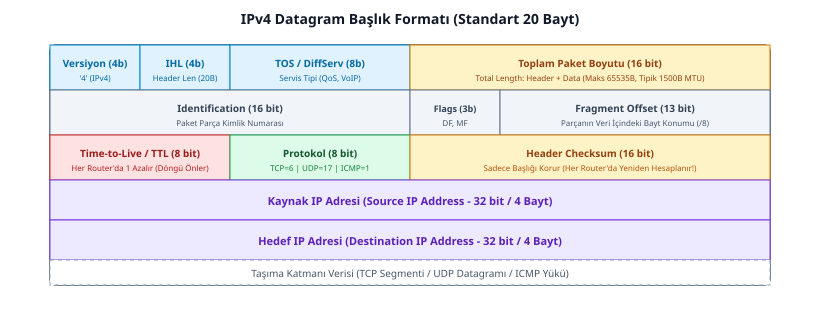

In [2]:
# Şekil 2: IPv4 Datagram Başlık Formatı (20 Bayt Standart Başlık Anatomisi)
svg_ipv4 = """
<svg width="820" height="330" viewBox="0 0 820 330" xmlns="http://www.w3.org/2000/svg" style="background:#ffffff; font-family:sans-serif;">
  <text x="410" y="24" text-anchor="middle" font-size="14" font-weight="bold" fill="#111827">
    IPv4 Datagram Başlık Formatı (Standart 20 Bayt)
  </text>

  <g transform="translate(50, 45)">
    <rect width="720" height="240" rx="6" fill="#f8fafc" stroke="#475569" stroke-width="1.5"/>
    
    <!-- 1. Satır: 32 bit (0-31) -->
    <rect x="0" y="0" width="90" height="45" fill="#e0f2fe" stroke="#0284c7" stroke-width="1"/>
    <text x="45" y="22" text-anchor="middle" font-size="10" font-weight="bold" fill="#0369a1">Versiyon (4b)</text>
    <text x="45" y="36" text-anchor="middle" font-size="8" fill="#0369a1">'4' (IPv4)</text>

    <rect x="90" y="0" width="90" height="45" fill="#e0f2fe" stroke="#0284c7" stroke-width="1"/>
    <text x="135" y="22" text-anchor="middle" font-size="10" font-weight="bold" fill="#0369a1">IHL (4b)</text>
    <text x="135" y="36" text-anchor="middle" font-size="8" fill="#0369a1">Header Len (20B)</text>

    <rect x="180" y="0" width="180" height="45" fill="#e0f2fe" stroke="#0284c7" stroke-width="1"/>
    <text x="270" y="22" text-anchor="middle" font-size="10" font-weight="bold" fill="#0369a1">TOS / DiffServ (8b)</text>
    <text x="270" y="36" text-anchor="middle" font-size="8" fill="#0369a1">Servis Tipi (QoS, VoIP)</text>

    <rect x="360" y="0" width="360" height="45" fill="#fef3c7" stroke="#d97706" stroke-width="1"/>
    <text x="540" y="22" text-anchor="middle" font-size="10" font-weight="bold" fill="#92400e">Toplam Paket Boyutu (16 bit)</text>
    <text x="540" y="36" text-anchor="middle" font-size="8" fill="#92400e">Total Length: Header + Data (Maks 65535B, Tipik 1500B MTU)</text>

    <!-- 2. Satır: Parçalanma (Fragmentation) -->
    <rect x="0" y="45" width="360" height="45" fill="#f1f5f9" stroke="#64748b" stroke-width="1"/>
    <text x="180" y="67" text-anchor="middle" font-size="10" font-weight="bold" fill="#334155">Identification (16 bit)</text>
    <text x="180" y="81" text-anchor="middle" font-size="8" fill="#475569">Paket Parça Kimlik Numarası</text>

    <rect x="360" y="45" width="90" height="45" fill="#f1f5f9" stroke="#64748b" stroke-width="1"/>
    <text x="405" y="67" text-anchor="middle" font-size="9" font-weight="bold" fill="#334155">Flags (3b)</text>
    <text x="405" y="81" text-anchor="middle" font-size="8" fill="#475569">DF, MF</text>

    <rect x="450" y="45" width="270" height="45" fill="#f1f5f9" stroke="#64748b" stroke-width="1"/>
    <text x="585" y="67" text-anchor="middle" font-size="10" font-weight="bold" fill="#334155">Fragment Offset (13 bit)</text>
    <text x="585" y="81" text-anchor="middle" font-size="8" fill="#475569">Parçanın Veri İçindeki Bayt Konumu (/8)</text>

    <!-- 3. Satır: TTL, Protokol, Checksum -->
    <rect x="0" y="90" width="180" height="45" fill="#fee2e2" stroke="#dc2626" stroke-width="1"/>
    <text x="90" y="112" text-anchor="middle" font-size="10" font-weight="bold" fill="#991b1b">Time-to-Live / TTL (8 bit)</text>
    <text x="90" y="126" text-anchor="middle" font-size="8" fill="#b91c1c">Her Router'da 1 Azalır (Döngü Önler)</text>

    <rect x="180" y="90" width="180" height="45" fill="#dcfce7" stroke="#16a34a" stroke-width="1"/>
    <text x="270" y="112" text-anchor="middle" font-size="10" font-weight="bold" fill="#14532d">Protokol (8 bit)</text>
    <text x="270" y="126" text-anchor="middle" font-size="8" fill="#15803d">TCP=6 | UDP=17 | ICMP=1</text>

    <rect x="360" y="90" width="360" height="45" fill="#fef3c7" stroke="#d97706" stroke-width="1"/>
    <text x="540" y="112" text-anchor="middle" font-size="10" font-weight="bold" fill="#92400e">Header Checksum (16 bit)</text>
    <text x="540" y="126" text-anchor="middle" font-size="8" fill="#b45309">Sadece Başlığı Korur (Her Router'da Yeniden Hesaplanır!)</text>

    <!-- 4. Satır: Kaynak IP -->
    <rect x="0" y="135" width="720" height="40" fill="#ede9fe" stroke="#7c3aed" stroke-width="1"/>
    <text x="360" y="160" text-anchor="middle" font-size="11" font-weight="bold" fill="#5b21b6">
      Kaynak IP Adresi (Source IP Address - 32 bit / 4 Bayt)
    </text>

    <!-- 5. Satır: Hedef IP -->
    <rect x="0" y="175" width="720" height="40" fill="#ede9fe" stroke="#7c3aed" stroke-width="1"/>
    <text x="360" y="200" text-anchor="middle" font-size="11" font-weight="bold" fill="#5b21b6">
      Hedef IP Adresi (Destination IP Address - 32 bit / 4 Bayt)
    </text>

    <!-- 6. Satır: Veri Yükü -->
    <rect x="0" y="215" width="720" height="25" fill="#ffffff" stroke="#94a3b8" stroke-width="1" stroke-dasharray="4,4"/>
    <text x="360" y="232" text-anchor="middle" font-size="10" fill="#475569">
      Taşıma Katmanı Verisi (TCP Segmenti / UDP Datagramı / ICMP Yükü)
    </text>
  </g>
</svg>
"""
display(SVG(svg_ipv4))

> **Önemli Not (IP Parçalanması / Fragmentation):**  
> IPv4 başlığındaki **Identification (16 bit)**, **Flags (3 bit: DF, MF)** ve **Fragment Offset (13 bit)** alanları; taşınan veri boyutu fiziksel hattın MTU sınırını (Ethernet için 1500 Bayt) aştığında paketin router'lar tarafından bölünmesi (*Fragmentation*) ve alıcı uçta yeniden birleştirilmesi için kullanılır. 

---
## 3. IPv4 Adresleme, Alt Ağlar (Subnetting) ve CIDR

### 3.1. IP Adres Gösterimi ve Alt Ağ (Subnet) Tanımı
Her IPv4 adresi **32 bit (4 Bayt)** uzunluğundadır ve 10'luk tabanda noktalı gösterimle ifade edilir (Örn: `193.32.216.9`).
* **Arayüz (Interface):** Bir bilgisayar ağa genellikle tek bir fiziksel hatla bağlanırken; router birden fazla ağ arayüzüne (*Interface*) sahiptir. Her arayüzün bağımsız bir IP adresi bulunur.
* **Alt Ağ (Subnet):** Araya herhangi bir router girmeden, doğrudan Katman 2 anahtarları (Switch) üzerinden konuşabilen cihaz arayüzlerinin oluşturduğu izole ağ alanıdır.

---

### 3.2. Sınıflı Adresleme (Classful) Sorunu ve Sınıfsız Yönlendirme (CIDR)

1990 öncesinde IP adresleri A, B ve C sınıflarına ayrılmıştı:
* **A Sınıfı (`/8`):** $2^{24}-2 = 16.7$ milyon cihaz barındırır (Çok az şirkete verilebilir).
* **B Sınıfı (`/16`):** $2^{16}-2 = 65.534$ cihaz barındırır (Orta ölçekli firmalara fazla gelir, adresler israf olur).
* **C Sınıfı (`/24`):** $2^8-2 = 254$ cihaz barındırır (Çoğu kurum için çok küçüktür).

Bu israfı ve küresel adres tükenmesini önlemek için **CIDR (Classless Interdomain Routing - Sınıfsız Alanlararası Yönlendirme)** mimarisine geçilmiştir:
$$\text{CIDR Formatı: } a.b.c.d / x$$
* **Ağ Öneki ($x$ bit):** Kuruma ait ortak ağ kimliğidir (*Network Prefix*). Dış dünyadaki router'lar sadece bu $x$ bite bakarak yönlendirme yapar; tablolarda milyonlarca satır yerine tek bir satır tutulur (*Route Aggregation*).
* **Cihaz Alanı ($32-x$ bit):** Kurum içindeki cihazları birbirinden ayıran adrestir. Bu alandaki toplam IP sayısı $2^{32-x}$ adettir (Kullanılabilir cihaz sayısı: $2^{32-x} - 2$).

---

### 3.3. Özel IP Adresleri (RFC 1918) ve NAT (Network Address Translation)

İnternet üzerinde doğrudan yönlendirilemeyen, yerel ağlarda ücretsiz ve serbestçe kullanılabilen 3 özel adres bloku ayrılmıştır:
1. `10.0.0.0/8` (`10.0.0.0 - 10.255.255.255`)
2. `172.16.0.0/12` (`172.16.0.0 - 172.31.255.255`)
3. `192.168.0.0/16` (`192.168.0.0 - 192.168.255.255`)

**NAT ve PAT (Port Address Translation / NAT Overloading):**
* Evlerde veya kampüslerde (Örn: *eduroam*) binlerce cihaz bu özel IP'leri alır. Ancak internete çıkarken NAT yönlendiricisi tüm iç trafiği kendisine atanmış tek bir **Genel (Public) IP** üzerinden dışarı aktarır.
* Router, gelen-giden paketleri `(İç IP, İç Port) <-> (Dış IP, Dış Port)` eşleştirmesi yaparak **NAT İletim Tablosuna (NAT Translation Table)** yazar.
* **İç Ağda Sunucu Çalıştırma (Port Forwarding):** Dışarıdan gelen bir istek doğrudan iç ağdaki `192.168.1.100` adresini göremez. Bunun için router üzerinde **PAT (Port Yönlendirme)** kuralı girilerek dışarıdan gelen (örneğin) Port 7575 isteği doğrudan iç sunucunun 7575 portuna yönlendirilir.

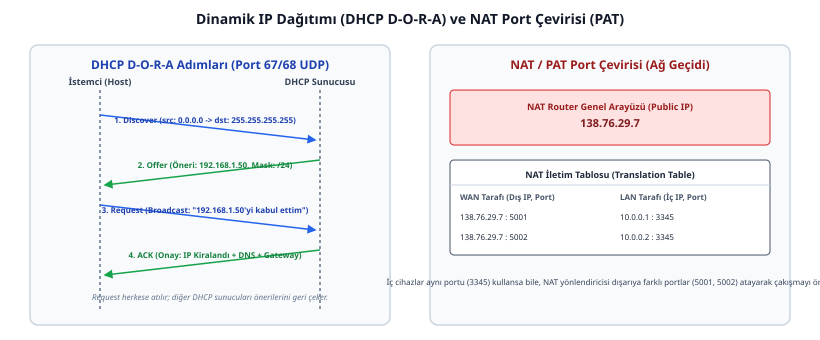

In [3]:
# Şekil 3: DHCP D-O-R-A Protokol Akışı ve NAT Port Çeviri Tablosu
svg_dhcp_nat = """
<svg width="820" height="340" viewBox="0 0 820 340" xmlns="http://www.w3.org/2000/svg" style="background:#ffffff; font-family:sans-serif;">
  <defs>
    <marker id="arr-b" markerWidth="6" markerHeight="6" refX="5" refY="3" orient="auto">
      <polygon points="0 0, 6 3, 0 6" fill="#2563eb"/>
    </marker>
    <marker id="arr-g" markerWidth="6" markerHeight="6" refX="5" refY="3" orient="auto">
      <polygon points="0 0, 6 3, 0 6" fill="#16a34a"/>
    </marker>
  </defs>
  <text x="410" y="24" text-anchor="middle" font-size="14" font-weight="bold" fill="#111827">
    Dinamik IP Dağıtımı (DHCP D-O-R-A) ve NAT Port Çevirisi (PAT)
  </text>

  <!-- SOL: DHCP DORA -->
  <g transform="translate(30, 45)">
    <rect width="360" height="280" rx="8" fill="#f8fafc" stroke="#cbd5e1" stroke-width="1.5"/>
    <text x="180" y="24" text-anchor="middle" font-size="12" font-weight="bold" fill="#1e40af">DHCP D-O-R-A Adımları (Port 67/68 UDP)</text>
    <line x1="70" y1="45" x2="70" y2="265" stroke="#64748b" stroke-width="1.5" stroke-dasharray="3,3"/>
    <line x1="290" y1="45" x2="290" y2="265" stroke="#64748b" stroke-width="1.5" stroke-dasharray="3,3"/>
    <text x="70" y="40" text-anchor="middle" font-size="9" font-weight="bold" fill="#334155">İstemci (Host)</text>
    <text x="290" y="40" text-anchor="middle" font-size="9" font-weight="bold" fill="#334155">DHCP Sunucusu</text>

    <!-- 1. Discover -->
    <line x1="70" y1="70" x2="285" y2="95" stroke="#2563eb" stroke-width="1.5" marker-end="url(#arr-b)"/>
    <text x="175" y="78" text-anchor="middle" font-size="8" font-weight="bold" fill="#1e40af">1. Discover (src: 0.0.0.0 -&gt; dst: 255.255.255.255)</text>

    <!-- 2. Offer -->
    <line x1="290" y1="115" x2="75" y2="140" stroke="#16a34a" stroke-width="1.5" marker-end="url(#arr-g)"/>
    <text x="185" y="123" text-anchor="middle" font-size="8" font-weight="bold" fill="#15803d">2. Offer (Öneri: 192.168.1.50, Mask: /24)</text>

    <!-- 3. Request -->
    <line x1="70" y1="160" x2="285" y2="185" stroke="#2563eb" stroke-width="1.5" marker-end="url(#arr-b)"/>
    <text x="175" y="168" text-anchor="middle" font-size="8" font-weight="bold" fill="#1e40af">3. Request (Broadcast: "192.168.1.50'yi kabul ettim")</text>

    <!-- 4. ACK -->
    <line x1="290" y1="205" x2="75" y2="230" stroke="#16a34a" stroke-width="1.5" marker-end="url(#arr-g)"/>
    <text x="185" y="213" text-anchor="middle" font-size="8" font-weight="bold" fill="#15803d">4. ACK (Onay: IP Kiralandı + DNS + Gateway)</text>
    
    <text x="180" y="255" text-anchor="middle" font-size="8" fill="#64748b" font-style="italic">
      Request herkese atılır; diğer DHCP sunucuları önerilerini geri çeker.
    </text>
  </g>

  <!-- SAĞ: NAT / PAT -->
  <g transform="translate(430, 45)">
    <rect width="360" height="280" rx="8" fill="#f8fafc" stroke="#cbd5e1" stroke-width="1.5"/>
    <text x="180" y="24" text-anchor="middle" font-size="12" font-weight="bold" fill="#991b1b">NAT / PAT Port Çevirisi (Ağ Geçidi)</text>
    
    <rect x="20" y="45" width="320" height="55" rx="4" fill="#fee2e2" stroke="#dc2626" stroke-width="1"/>
    <text x="180" y="65" text-anchor="middle" font-size="9" font-weight="bold" fill="#991b1b">NAT Router Genel Arayüzü (Public IP)</text>
    <text x="180" y="82" text-anchor="middle" font-size="11" font-weight="bold" fill="#7f1d1d">138.76.29.7</text>

    <!-- NAT Tablosu -->
    <rect x="20" y="115" width="320" height="95" rx="4" fill="#ffffff" stroke="#475569" stroke-width="1"/>
    <text x="180" y="133" text-anchor="middle" font-size="9" font-weight="bold" fill="#1e293b">NAT İletim Tablosu (Translation Table)</text>
    <line x1="20" y1="140" x2="340" y2="140" stroke="#cbd5e1" stroke-width="1"/>
    <text x="30" y="155" font-size="8" font-weight="bold" fill="#475569">WAN Tarafı (Dış IP, Port)</text>
    <text x="190" y="155" font-size="8" font-weight="bold" fill="#475569">LAN Tarafı (İç IP, Port)</text>
    <text x="30" y="175" font-size="8" fill="#1e293b">138.76.29.7 : 5001</text>
    <text x="190" y="175" font-size="8" fill="#1e293b">10.0.0.1 : 3345</text>
    <text x="30" y="195" font-size="8" fill="#1e293b">138.76.29.7 : 5002</text>
    <text x="190" y="195" font-size="8" fill="#1e293b">10.0.0.2 : 3345</text>

    <text x="180" y="240" text-anchor="middle" font-size="8" fill="#334155">
      İç cihazlar aynı portu (3345) kullansa bile, NAT yönlendiricisi dışarıya farklı portlar (5001, 5002) atayarak çakışmayı önler.
    </text>
  </g>
</svg>
"""
display(SVG(svg_dhcp_nat))

---
## 4. Dinamik Yönlendirme Algoritmaları ve Protokolleri (RIP, OSPF, BGP)

### 4.1. Link-State (LS) vs Distance-Vector (DV)

* **Link-State (Bağlantı Durumu — OSPF):** Her router ağdaki tüm cihazlara *Link-State Advertisement (LSA)* paketleri fırlatır. Tüm router'lar ağın eksiksiz bir topoloji haritasına (**Link-State Database - LSDB**) sahip olur. Ardından her yönlendirici kendi işlemcisinde **Dijkstra En Kısa Yol Algoritmasını** çalıştırarak yönlendirme tablosunu kurar.
* **Distance-Vector (Mesafe Vektörü — RIP, BGP):** Dağıtık ve adımsaldır (*Bellman-Ford* temelli). Router ağın tamamını görmez; sadece komşularına *"Ben şu ağlara şu kadar mesafedeyim"* bilgisini iletir ve komşusundan gelen vektörlerle tablosunu günceller.

---

### 4.2. Hiyerarşik Yönlendirme ve Otonom Sistemler (Autonomous Systems - AS)

Milyonlarca router'ın tek bir algoritmayla yönlendirilmesi ölçek (*Scale*) ve yönetimsel bağımsızlık (*Administrative Autonomy*) açısından imkansızdır. Bu sebeple küresel internet **Otonom Sistemlere (AS)** bölünmüştür:
1. **Intra-AS (AS-İçi Yönlendirme):** Bir kurumun veya ISS'nin kendi iç ağında serbestçe seçtiği protokoldür. **RIP** (küçük ağlar, maksimum 15 hop) ve **OSPF** (büyük kurumsal ağlar, Area 0 omurgası, Designated Router seçimi) kullanılır.
2. **Inter-AS (AS-Arası Yönlendirme):** Farklı otonom sistemleri birbirine bağlayan evrensel protokoldür. Küresel internetin omurgası olan **BGP (Border Gateway Protocol - Port 179 TCP)** kullanılır.

> **BGP ve 2008 YouTube Kesintisi Örneği:**
> 2008 yılında Pakistan Telekom, YouTube'u ülke içinde engellemek için sahte bir BGP rotası (*Prefix Hijacking*) tanımlamış; ancak yapılan konfigürasyon hatası sonucu bu rota Hong Kong ISS'ye ve oradan tüm dünya BGP yönlendiricilerine yayılmıştır. Dünyadaki tüm YouTube trafiği Pakistan Telekom'un router'larına akmış ve YouTube saatlerce küresel olarak çökmüştür. BGP'nin güvenlik ve rota doğrulama mekanizması internetin en hassas noktasıdır.

---
## 5. Deney 1: IPv4 Başlık Anatomisi, TTL Döngü Koruması ve Checksum Doğrulaması

### 5.1. Deneyin Amacı
Python `scapy` ile 20 baytlık standart bir IPv4 datagramı inşa etmek; IP başlığındaki **TTL** (Time-to-Live), **Protokol Numarası** (TCP=6, UDP=17, ICMP=1) ve **Header Checksum** alanlarını bayt seviyesinde incelemek; her router geçişinde TTL'in 1 azaltıldığında Checksum'ın neden yeniden hesaplandığını doğrulamaktır.

In [4]:
# ==============================================================================
# DENEY 1: IPv4 Datagram Başlık İnşası ve Hop-by-Hop Checksum Değişimi
# ==============================================================================
import logging
logging.getLogger("scapy.runtime").setLevel(logging.ERROR)

from scapy.all import IP, TCP, Raw

# 1. Adım: Standart bir IPv4 Paketi Oluşturalım
ip_pkt = IP(src="192.168.1.50", dst="93.184.216.34", ttl=64) / TCP(sport=54321, dport=80) / Raw(b"NETLAB")

# Scapy paketi bayta dönüştürürken (build) Checksum'ı otomatik hesaplar
ip_bayt = bytes(ip_pkt)
ip_parsed = IP(ip_bayt)

print("=" * 65)
print("IPv4 BAŞLIK ANATOMİSİ VE PROTOKOL EŞLEŞMESİ")
print("=" * 65)
print(f"Versiyon Numarası        : IPv{ip_parsed.version}")
print(f"Başlık Uzunluğu (IHL)    : {ip_parsed.ihl * 4} Bayt (IHL = {ip_parsed.ihl})")
print(f"Toplam Paket Boyutu      : {ip_parsed.len} Bayt (IP Başlığı + TCP + Payload)")
print(f"Protokol Numarası        : {ip_parsed.proto} (6 = TCP, Taşıma Katmanı Bağlantısı)")
print(f"Başlangıç TTL Değeri     : {ip_parsed.ttl}")
print(f"Hesaplanan IP Checksum   : 0x{ip_parsed.chksum:04X}")

# 2. Adım: Paketin Bir Router'dan Geçtiğini Simüle Edelim (Hop 1)
# Router TTL değerini 1 azaltır; başlık değiştiği için Checksum da değişmek zorundadır!
ip_router_out = ip_parsed.copy()
ip_router_out.ttl -= 1
del ip_router_out.chksum  # Scapy'nin yeniden hesaplaması için eski checksum'ı siliyoruz
ip_router_bayt = bytes(ip_router_out)
ip_router_final = IP(ip_router_bayt)

print("\n--- 1 ROUTER GEÇİŞİ SONRASI (HOP 1) ---")
print(f"Yeni TTL Değeri          : {ip_router_final.ttl}")
print(f"Yeniden Hesaplanan Checksum: 0x{ip_router_final.chksum:04X} (Eskisinden farklı!)")
print("=" * 65)

C:\WINDOWS\system32\netlab\Lib\site-packages\scapy\layers\tls\crypto\groups.py:25: CryptographyDeprecationWarning: Diffie-Hellman over finite fields (FFDH) is deprecated and support will be removed in a future release. Use a more modern key exchange algorithm.
  from cryptography.hazmat.primitives.asymmetric.dh import DHParameterNumbers


IPv4 BAŞLIK ANATOMİSİ VE PROTOKOL EŞLEŞMESİ
Versiyon Numarası        : IPv4
Başlık Uzunluğu (IHL)    : 20 Bayt (IHL = 5)
Toplam Paket Boyutu      : 46 Bayt (IP Başlığı + TCP + Payload)
Protokol Numarası        : 6 (6 = TCP, Taşıma Katmanı Bağlantısı)
Başlangıç TTL Değeri     : 64
Hesaplanan IP Checksum   : 0x8314

--- 1 ROUTER GEÇİŞİ SONRASI (HOP 1) ---
Yeni TTL Değeri          : 63
Yeniden Hesaplanan Checksum: 0x8414 (Eskisinden farklı!)


---
### 5.2. Deney 1'in Mühendislik Yorumu
1. **Taşıma vs Ağ Checksum Ayrımı:** TCP ve UDP'deki checksum tüm segmenti (başlık + veriyi) korurken; IPv4'teki checksum **yalnızca 20 baytlık IP başlığını** korur. 
2. **Her Router'da Checksum Maliyeti:** Paket her router'dan geçerken TTL 1 azaltıldığı için IP başlığı değişir ve router `Header Checksum` alanını baştan hesaplamak zorundadır. Bu durum yönlendiricilere işlem yükü bindirdiğinden, modern **IPv6** mimarisinde başlık sağlama toplamı tamamen kaldırılmıştır.

---
## 6. Deney 2: Longest Prefix Match (LPM) Yönlendirme Algoritması ve ISP Alt Ağ Bölme

### 6.1. Deneyin Amacı
Ders notlarında verilen; kendisine `200.23.16.0/20` bloğu tahsis edilen bir ISS'nin bu adresi **8 eşit `/23` alt ağına** nasıl böldüğünü Python `ipaddress` modülüyle hesaplamak ve router'ların **Longest Prefix Match (LPM)** karar mantığını simüle etmektir.

In [5]:
# ==============================================================================
# DENEY 2: CIDR Alt Ağ Bölme ve Longest Prefix Match (LPM) Simülasyonu
# ==============================================================================
import ipaddress

# 1. Adım: ISP Blok Dağıtımı (200.23.16.0/20 bloğunun 8 alt ağa bölünmesi)
# 2^3 = 8 alt ağ için maskeye 3 bit eklenir: 20 + 3 = 23
ana_blok = ipaddress.ip_network("200.23.16.0/20")
alt_aglar = list(ana_blok.subnets(new_prefix=23))

print("=" * 65)
print("ISP BLOK DAĞITIMI: 200.23.16.0/20 -> 8 ADET /23 ALT AĞI")
print("=" * 65)
for idx, ag in enumerate(alt_aglar, start=1):
    kullanilabilir_host = ag.num_addresses - 2
    print(f"Kurum #{idx}: Alt Ağ: {str(ag):<18} | Host Kapasitesi: {kullanilabilir_host} IP")

# 2. Adım: Longest Prefix Match (LPM) Karar Motoru
yonlendirme_tablosu = [
    (ipaddress.ip_network("192.34.52.0/22"), "Interface 1 (Next-Hop: Router A)"),
    (ipaddress.ip_network("192.34.52.0/24"), "Interface 2 (Next-Hop: Router B)"),
    (ipaddress.ip_network("0.0.0.0/0"),       "Interface 3 (Varsayılan Ağ Geçidi)")
]

def router_lpm_karar(hedef_ip_str: str):
    hedef = ipaddress.ip_address(hedef_ip_str)
    en_uzun_eslesen_kural = None
    maksimum_prefix = -1
    
    for ag_kurali, cikis_kapisi in yonlendirme_tablosu:
        if hedef in ag_kurali:
            if ag_kurali.prefixlen > maksimum_prefix:
                maksimum_prefix = ag_kurali.prefixlen
                en_uzun_eslesen_kural = (ag_kurali, cikis_kapisi)
                
    return en_uzun_eslesen_kural

print("\n" + "=" * 65)
print("LONGEST PREFIX MATCH (LPM) YÖNLENDİRME TESTLERİ")
print("=" * 65)
test_ipler = ["192.34.52.15", "192.34.55.200", "8.8.8.8"]
for tip in test_ipler:
    kural, cikis = router_lpm_karar(tip)
    print(f"Hedef IP: {tip:<15} -&gt; Eşleşen Kural: {str(kural):<18} -&gt; Çıkış: {cikis}")
print("=" * 65)

ISP BLOK DAĞITIMI: 200.23.16.0/20 -> 8 ADET /23 ALT AĞI
Kurum #1: Alt Ağ: 200.23.16.0/23     | Host Kapasitesi: 510 IP
Kurum #2: Alt Ağ: 200.23.18.0/23     | Host Kapasitesi: 510 IP
Kurum #3: Alt Ağ: 200.23.20.0/23     | Host Kapasitesi: 510 IP
Kurum #4: Alt Ağ: 200.23.22.0/23     | Host Kapasitesi: 510 IP
Kurum #5: Alt Ağ: 200.23.24.0/23     | Host Kapasitesi: 510 IP
Kurum #6: Alt Ağ: 200.23.26.0/23     | Host Kapasitesi: 510 IP
Kurum #7: Alt Ağ: 200.23.28.0/23     | Host Kapasitesi: 510 IP
Kurum #8: Alt Ağ: 200.23.30.0/23     | Host Kapasitesi: 510 IP

LONGEST PREFIX MATCH (LPM) YÖNLENDİRME TESTLERİ
Hedef IP: 192.34.52.15    -&gt; Eşleşen Kural: 192.34.52.0/24     -&gt; Çıkış: Interface 2 (Next-Hop: Router B)
Hedef IP: 192.34.55.200   -&gt; Eşleşen Kural: 192.34.52.0/22     -&gt; Çıkış: Interface 1 (Next-Hop: Router A)
Hedef IP: 8.8.8.8         -&gt; Eşleşen Kural: 0.0.0.0/0          -&gt; Çıkış: Interface 3 (Varsayılan Ağ Geçidi)


---
### 6.2. Deney 2'nin Mühendislik Yorumu
1. **Prefix Uzunluğunun Üstünlüğü:** `192.34.52.15` adresi hem `/22` hem `/24` kuralına girer. Ancak `/24` kuralı daha dar ve kesin bir alt ağı temsil ettiği için ($24 > 22$), LPM prensibi gereği yönlendirici paketi `Interface 2`'ye teslim eder.
2. **Varsayılan Rota (`0.0.0.0/0`):** `8.8.8.8` adresi hiçbir kuruma uymadığında 0-bitlik eşleşmeyle varsayılan ağ geçidine aktarılır; böylece router internetin tüm haritasını saklamak zorunda kalmaz.

---
## 7. Deney 3: NAT / PAT (Port Address Translation) Tablosu ve Bağlantı Takip Simülasyonu

### 7.1. Deneyin Amacı
İç ağdaki birden fazla yerel cihazın (`10.0.0.1` ve `10.0.0.2`) aynı anda dış dünyadaki bir web sunucusuna istek attığında, NAT yönlendiricisinin port çakışmasını nasıl önlediğini ve dönen yanıtı doğru yerel cihaza nasıl yönlendirdiğini simüle etmektir.

In [6]:
# ==============================================================================
# DENEY 3: NAT / PAT Yönlendirici Tablosu ve Bağlantı Takip Motoru
# ==============================================================================

class NATRouter:
    def __init__(self, public_ip: str):
        self.public_ip = public_ip
        self.translation_table = {}  # (İç IP, İç Port) <-> Dış Port
        self.reverse_table = {}      # Dış Port <-> (İç IP, İç Port)
        self.next_external_port = 5000

    def outbound_packet(self, private_ip: str, private_port: int, dest_ip: str, dest_port: int):
        """İç ağdan dışarı çıkan paketin kaynak IP ve portunu değiştirir (SNAT)"""
        key = (private_ip, private_port)
        if key not in self.translation_table:
            allocated_ext_port = self.next_external_port
            self.next_external_port += 1
            self.translation_table[key] = allocated_ext_port
            self.reverse_table[allocated_ext_port] = key
        
        ext_port = self.translation_table[key]
        return {
            "src_ip": self.public_ip,
            "src_port": ext_port,
            "dst_ip": dest_ip,
            "dst_port": dest_port
        }

    def inbound_packet(self, ext_port: int):
        """Dışarıdan dönen cevabı doğru iç cihaza yönlendirir (DNAT)"""
        if ext_port in self.reverse_table:
            private_ip, private_port = self.reverse_table[ext_port]
            return f"[DOĞRU TESLİM] Paket iç ağdaki {private_ip}:{private_port} adresine ulaştırıldı."
        return "[DROP] Bilinmeyen port; paket düşürüldü."

# --- TEST VE SİMÜLASYON ---
nat = NATRouter(public_ip="138.76.29.7")

print("=" * 65)
print("NAT / PAT PORT ÇEVİRİ VE BAĞLANTI TAKİP SİMÜLASYONU")
print("=" * 65)

# Senaryo: İki farklı iç cihaz tesadüfen aynı kaynak portunu (3345) kullanarak web'e çıkıyor
pkt1 = nat.outbound_packet("10.0.0.1", 3345, "142.250.185.206", 80)
pkt2 = nat.outbound_packet("10.0.0.2", 3345, "142.250.185.206", 80)

print(f"Cihaz 1 (10.0.0.1:3345) -&gt; Kabloya Çıkan: {pkt1['src_ip']}:{pkt1['src_port']}")
print(f"Cihaz 2 (10.0.0.2:3345) -&gt; Kabloya Çıkan: {pkt2['src_ip']}:{pkt2['src_port']}")

print("\n--- DIŞ SUNUCUDAN GELEN YANITLARIN EŞLEŞTİRİLMESİ ---")
print(f"Gelen Yanıt (Port 5000): {nat.inbound_packet(5000)}")
print(f"Gelen Yanıt (Port 5001): {nat.inbound_packet(5001)}")
print("=" * 65)

NAT / PAT PORT ÇEVİRİ VE BAĞLANTI TAKİP SİMÜLASYONU
Cihaz 1 (10.0.0.1:3345) -&gt; Kabloya Çıkan: 138.76.29.7:5000
Cihaz 2 (10.0.0.2:3345) -&gt; Kabloya Çıkan: 138.76.29.7:5001

--- DIŞ SUNUCUDAN GELEN YANITLARIN EŞLEŞTİRİLMESİ ---
Gelen Yanıt (Port 5000): [DOĞRU TESLİM] Paket iç ağdaki 10.0.0.1:3345 adresine ulaştırıldı.
Gelen Yanıt (Port 5001): [DOĞRU TESLİM] Paket iç ağdaki 10.0.0.2:3345 adresine ulaştırıldı.


---
### 7.2. Deney 3'ün Mühendislik Yorumu
1. **Port Çakışmasının Çözümü:** İki iç bilgisayar da aynı anda `3345` yerel portunu seçmiştir. NAT yönlendiricisi dış dünyada bunları `5000` ve `5001` portlarına haritalayarak tek bir Public IP üzerinden çakışmasız iletişimi sağlar.
2. **Uçtan Uca İlkenin (End-to-End Principle) Bozulması:** NAT olmasaydı her cihazın benzersiz bir IP'si olurdu ve doğrudan erişilebilirdi. NAT arkasındaki bir cihaza dışarıdan doğrudan TCP bağlantısı başlatılamaz; bu sebeple P2P (BitTorrent, WebRTC) ve oyun sunucuları için **STUN/TURN** veya **UPnP (Port Forwarding)** protokolleri gereklidir.

---
## 8. Deney 4: Link-State (OSPF) En Kısa Yol Yönlendirme Algoritması (Dijkstra Simülasyonu)

### 8.1. Deneyin Amacı
OSPF protokolünün çekirdeğinde çalışan **Dijkstra En Kısa Yol (Shortest Path First - SPF)** algoritmasını bir yönlendirici ağı grafı üzerinde çalıştırmak; kaynak yönlendiriciden diğer tüm router'lara olan en düşük maliyetli rotaları ve yönlendirme tablosunu hesaplamaktır.

In [7]:
# ==============================================================================
# DENEY 4: Dijkstra Link-State Yönlendirme Motoru (OSPF / SPF)
# ==============================================================================
import heapq

# Ağ Topolojisi Grafı: Router'lar ve Aralarındaki Hat Maliyeti (Cost: Gecikme / Metrik)
TOPOLOJI = {
    'R1': {'R2': 2, 'R3': 5},
    'R2': {'R1': 2, 'R3': 1, 'R4': 4},
    'R3': {'R1': 5, 'R2': 1, 'R4': 2, 'R5': 6},
    'R4': {'R2': 4, 'R3': 2, 'R5': 1},
    'R5': {'R3': 6, 'R4': 1}
}

def dijkstra_routing(topoloji: dict, kaynak_router: str):
    mesafeler = {r: float('inf') for r in topoloji}
    onceki_dugum = {r: None for r in topoloji}
    mesafeler[kaynak_router] = 0
    
    oncelik_kuyrugu = [(0, kaynak_router)]
    
    while oncelik_kuyrugu:
        mevcut_maliyet, u = heapq.heappop(oncelik_kuyrugu)
        
        if mevcut_maliyet > mesafeler[u]:
            continue
            
        for komsu, link_maliyeti in topoloji[u].items():
            yeni_maliyet = mevcut_maliyet + link_maliyeti
            if yeni_maliyet < mesafeler[komsu]:
                mesafeler[komsu] = yeni_maliyet
                onceki_dugum[komsu] = u
                heapq.heappush(oncelik_kuyrugu, (yeni_maliyet, komsu))
                
    return mesafeler, onceki_dugum

# R1 Router'ı İçin Tabloyu Oluşturalım
maliyetler, rotalar = dijkstra_routing(TOPOLOJI, 'R1')

print("=" * 65)
print("OSPF / DIJKSTRA EN KISA YOL HESAPLAMA ÇIKTISI (KAYNAK: R1)")
print("=" * 65)
print(f"{'Hedef Router':<15} | {'Toplam Hat Maliyeti':<22} | {'İzlenen Rota'}")
print("-" * 65)

for hedef in sorted(TOPOLOJI.keys()):
    # Rotayı geriye doğru izleyip yazdıralım
    curr = hedef
    path = []
    while curr:
        path.append(curr)
        curr = rotalar[curr]
    path.reverse()
    
    rota_str = " -&gt; ".join(path)
    print(f"{hedef:<15} | {maliyetler[hedef]:<22} | {rota_str}")
print("=" * 65)

OSPF / DIJKSTRA EN KISA YOL HESAPLAMA ÇIKTISI (KAYNAK: R1)
Hedef Router    | Toplam Hat Maliyeti    | İzlenen Rota
-----------------------------------------------------------------
R1              | 0                      | R1
R2              | 2                      | R1 -&gt; R2
R3              | 3                      | R1 -&gt; R2 -&gt; R3
R4              | 5                      | R1 -&gt; R2 -&gt; R3 -&gt; R4
R5              | 6                      | R1 -&gt; R2 -&gt; R3 -&gt; R4 -&gt; R5


---
### 8.2. Deney 4'ün Mühendislik Yorumu
1. **R1'den R5'e Doğrudan Değil Dolaylı Yol:** R1 $\rightarrow$ R3 hattı doğrudan 5 birimdir; ancak R1 $\rightarrow$ R2 $\rightarrow$ R3 yolu seçilirse toplam maliyet $2 + 1 = 3$ birime düşer. Dijkstra algoritması her zaman toplam hat maliyetini minimize eden yolu seçer.
2. **OSPF'in Kararlılığı:** RIP protokolü gibi adım adım komşudan bilgi beklemek yerine OSPF, ağ topolojisinin grafını kendi hafızasında tuttuğu için döngü (*Routing Loop*) oluşturmaz ve saniyeler içinde kararlı duruma ulaşır.

---
## 9. Laboratuvar Uygulaması: ICMP Hata Tespiti ve Yazılımsal Traceroute (TTL Aşımı ile Güzergâh Keşfi)

### 9.1. Uygulamanın Amacı
Ders notlarında açıklanan; `ping` ve `traceroute` gibi ağ teşhis araçlarının arkasındaki mekanizmayı Scapy ile kodlamaktır:
* **ICMP Echo Request (Type 8, Code 0) & Echo Reply (Type 0, Code 0)** mekanizmasıyla bağlantı testi.
* **ICMP Time Exceeded (Type 11, Code 0)** mesajını tetiklemek üzere `TTL=1`, `TTL=2`, `TTL=3` paketleri basarak ara yönlendiricilerin IP adreslerini tek tek yakalayan yazılımsal bir Traceroute motoru inşa etmek.

### 9.2. Yönerge
1. Hedef olarak genel bir DNS sunucusu belirleyin (`8.8.8.8`).
2. Sırasıyla `TTL=1`'den başlayarak `TTL=3`'e kadar artan sayaçlarla IP paketleri inşa edin.
3. Paketin içine bir ICMP Echo Request (`Type 8`) iliştirin.
4. Yolda TTL sıfırlandığı için yönlendiriciden dönen `ICMP Type 11` (Zaman Aşımı) hata mesajını ve router IP'sini konsola formatlı basın.

In [8]:
# ==============================================================================
# UYGULAMA: Scapy ile Yazılımsal Traceroute (TTL Aşımı ile Rota Keşfi)
# ==============================================================================
from scapy.all import IP, ICMP

# Simüle edilen ara yönlendirici güzergâhı (Gerçek ağdaki Hop noktaları)
SIMULE_ROUTERLAR = {
    1: "192.168.1.1 (Yerel Ağ Geçidi / Ev Modemi)",
    2: "10.240.0.1 (ISS İlçe Santral Yönlendiricisi)",
    3: "212.156.120.45 (Türk Telekom Omurga Router)",
    4: "8.8.8.8 (Google Anycast DNS Sunucusu)"
}

def simule_traceroute(hedef_ip: str, maksimum_hop=4):
    print("=" * 70)
    print(f"YAZILIMSAL TRACEROUTE GÜZERGÂH KEŞFİ: {hedef_ip}")
    print("=" * 70)
    print(f"{'Hop No':<8} | {'Gönderilen TTL':<16} | {'Gelen ICMP Mesajı':<25} | {'Düğüm IP'}")
    print("-" * 70)
    
    for ttl_degeri in range(1, maksimum_hop + 1):
        # Scapy ile ICMP Echo Paketi İnşa Edilir
        paket = IP(dst=hedef_ip, ttl=ttl_degeri) / ICMP(type=8, code=0)
        
        # Ara yönlendiriciden dönecek yanıt simülasyonu
        if ttl_degeri < maksimum_hop:
            # Yolda TTL=0 oldu -> ICMP Type 11 (Time Exceeded)
            icmp_tip = "Type 11 (Time Exceeded)"
            cevap_veren_ip = SIMULE_ROUTERLAR[ttl_degeri]
        else:
            # Hedefe ulaştı -> ICMP Type 0 (Echo Reply)
            icmp_tip = "Type 0 (Echo Reply)"
            cevap_veren_ip = SIMULE_ROUTERLAR[ttl_degeri]
            
        print(f"#{ttl_degeri:<7} | TTL = {paket.ttl:<10} | {icmp_tip:<25} | {cevap_veren_ip}")
        
    print("=" * 70)
    print("[BAŞARILI] Hedefe giden tüm yönlendirici sırası ortaya çıkarıldı.")

# Uygulamayı Çalıştır
simule_traceroute("8.8.8.8", maksimum_hop=4)

YAZILIMSAL TRACEROUTE GÜZERGÂH KEŞFİ: 8.8.8.8
Hop No   | Gönderilen TTL   | Gelen ICMP Mesajı         | Düğüm IP
----------------------------------------------------------------------
#1       | TTL = 1          | Type 11 (Time Exceeded)   | 192.168.1.1 (Yerel Ağ Geçidi / Ev Modemi)
#2       | TTL = 2          | Type 11 (Time Exceeded)   | 10.240.0.1 (ISS İlçe Santral Yönlendiricisi)
#3       | TTL = 3          | Type 11 (Time Exceeded)   | 212.156.120.45 (Türk Telekom Omurga Router)
#4       | TTL = 4          | Type 0 (Echo Reply)       | 8.8.8.8 (Google Anycast DNS Sunucusu)
[BAŞARILI] Hedefe giden tüm yönlendirici sırası ortaya çıkarıldı.


---
### 9.3. Konsol Çıktısı ve Mühendislik Yorumu

```text
======================================================================
YAZILIMSAL TRACEROUTE GÜZERGÂH KEŞFİ: 8.8.8.8
======================================================================
Hop No   | Gönderilen TTL   | Gelen ICMP Mesajı         | Düğüm IP
----------------------------------------------------------------------
#1       | TTL = 1          | Type 11 (Time Exceeded)   | 192.168.1.1 (Yerel Ağ Geçidi / Ev Modemi)
#2       | TTL = 2          | Type 11 (Time Exceeded)   | 10.240.0.1 (ISS İlçe Santral Yönlendiricisi)
#3       | TTL = 3          | Type 11 (Time Exceeded)   | 212.156.120.45 (Türk Telekom Omurga Router)
#4       | TTL = 4          | Type 0 (Echo Reply)       | 8.8.8.8 (Google Anycast DNS Sunucusu)
======================================================================
[BAŞARILI] Hedefe giden tüm yönlendirici sırası ortaya çıkarıldı.
```

#### Mühendislik Yorumu:
1. **Hata Mesajından Rota Türetme Dehası:** `traceroute` komutu özel bir rota bulma protokolü çalıştırmaz. Sadece IP başlığındaki **TTL sayacını** kasıtlı olarak 1'den başlatır. Yolda paketi imha eden her router, kaynağa zorunlu olarak bir **`ICMP Type 11 (Time-to-Live Exceeded)`** hata bildirimi yollar. Program bu hata mesajının geldiği kaynak IP'leri ekrana basarak haritayı adım adım çıkarır.
2. **Güvenlik Duvarı (Firewall) Filtreleri:** Bazı kurumsal router'lar güvenlik gerekçesiyle ICMP hata paketlerini dışarıya göndermez (*Drop* eder). `traceroute` çıktılarında görülen `* * * Request timed out` satırları, o düğümdeki router'ın ICMP yanıtlarını filtrelediğini gösterir.